<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/Notebook12_Phase3_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick train.csv

Saving train.csv to train.csv


{'train.csv': b'school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other,G3\n0,1,19,0,1,1,3,3,1,2,1,0,0,0,1,1,1,0,1,4,5,3,1,2,5,0,15,12,0,1,0,0,0,0,1,0,0,0,1,0,0,12\n1,0,18,1,1,1,2,3,2,1,0,0,1,1,0,1,1,1,1,5,2,3,1,2,4,0,11,10,0,0,0,0,0,0,1,0,0,0,0,0,0,10\n0,0,19,0,1,1,2,3,1,3,1,0,0,0,0,1,1,1,1,4,1,2,1,1,3,20,13,11,0,1,0,0,0,1,0,0,0,0,1,0,1,11\n0,1,15,1,1,1,4,3,1,2,0,0,1,1,1,1,1,1,0,4,3,3,2,3,5,6,9,9,0,0,0,1,0,1,0,0,1,0,0,1,0,10\n0,1,17,1,0,0,4,1,2,1,0,0,0,1,1,1,1,1,1,4,5,4,2,4,5,20,8,8,0,0,1,0,0,1,0,0,1,0,0,1,0,8\n1,0,18,1,0,1,3,1,1,2,0,0,1,1,0,1,1,1,0,4,3,4,1,1,1,0,7,9,0,0,0,1,0,0,1,0,0,0,0,1,0,8\n0,0,16,1,1,1,4,4,1,3,0,0,1,1,1,1,1,1,0,3,2,3,1,2,2,6,13,14,0,0,1,0,0,0,1,0,0,0,

In [2]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick linreg_scratch.py

Saving linreg_scratch.py to linreg_scratch.py


{'linreg_scratch.py': b'# Cell 11: save your model so later days can import it\nimport numpy as np\n\ndef gradient_descent(X, y, lr=0.05, epochs=3000):\n    w, b, history = np.zeros(X.shape[1]), 0.0, []\n    n = len(y)\n    for _ in range(epochs):\n        error = X @ w + b - y\n        w -= lr * (2 / n) * (X.T @ error)\n        b -= lr * (2 / n) * error.sum()\n        history.append(np.mean(error ** 2))\n    return w, b, history\n\nclass LinearRegressionScratch:\n    def __init__(self, lr=0.05, epochs=3000):\n        self.lr, self.epochs = lr, epochs\n\n    def fit(self, X, y):\n        X, y = np.asarray(X, float), np.asarray(y, float)\n        self.mu, self.sigma = X.mean(axis=0), X.std(axis=0)\n        self.sigma[self.sigma == 0] = 1.0\n        self.w, self.b, self.history = gradient_descent((X - self.mu) / self.sigma, y, self.lr, self.epochs)\n        return self\n\n    def predict(self, X):\n        return ((np.asarray(X, float) - self.mu) / self.sigma) @ self.w + self.b\n'}

In [3]:
# Cell 1: setup, one set of folds for everything
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (RepeatedKFold, RepeatedStratifiedKFold, KFold,
                                     StratifiedKFold, GridSearchCV, cross_validate)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import make_scorer, precision_score, f1_score
from linreg_scratch import LinearRegressionScratch      # your Day 11 file

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
y = train["G3"]
y_risk = (y < 10).astype(int)
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

cv_reg = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
cv_clf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
inner_reg = KFold(n_splits=5, shuffle=True, random_state=1)
inner_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

print("Training students:", len(train), "| at risk:", y_risk.sum(), f"({y_risk.mean():.1%})")
print("Scores per model: 5 folds x 3 repeats = 15")

Training students: 285 | at risk: 73 (25.6%)
Scores per model: 5 folds x 3 repeats = 15


In [5]:
# Cell 2: the regression models, every tuned one is tuned INSIDE each outer fold (nested CV)
tree_grid = {"max_depth": [2, 3, 4, 5, 6, 8], "min_samples_leaf": [1, 5, 10, 20]}

reg_models = {
    "Baseline (mean)": DummyRegressor(),
    "Linear": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 40))),
    "Lasso": make_pipeline(StandardScaler(),
                           LassoCV(alphas=np.logspace(-3, 0.5, 30), cv=5, max_iter=20000)),
    "Tree (tuned)": GridSearchCV(DecisionTreeRegressor(random_state=42), tree_grid,
                                 cv=inner_reg, scoring="neg_root_mean_squared_error", n_jobs=-1),
}
reg_scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

In [6]:
# Cell 3: run every regression model on both feature sets
fold_scores = {}
for fname, X in feature_sets.items():
    for mname, m in reg_models.items():
        r = cross_validate(m, X, y, cv=cv_reg, scoring=reg_scoring)
        fold_scores[(fname, mname)] = {"rmse": -r["test_rmse"], "mae": -r["test_mae"], "r2": r["test_r2"]}

    # your from-scratch model from Day 11, on exactly the same folds
    rm, ma, r2 = [], [], []
    for tr, va in cv_reg.split(X):
        m = LinearRegressionScratch(lr=0.05, epochs=3000).fit(X.iloc[tr], y.iloc[tr])
        p, yt = m.predict(X.iloc[va]), y.iloc[va].values
        rm.append(np.sqrt(np.mean((yt - p) ** 2)))
        ma.append(np.mean(np.abs(yt - p)))
        r2.append(1 - np.sum((yt - p) ** 2) / np.sum((yt - yt.mean()) ** 2))
    fold_scores[(fname, "Linear (from scratch)")] = {"rmse": np.array(rm), "mae": np.array(ma), "r2": np.array(r2)}

rows = []
for (fname, mname), s in fold_scores.items():
    base_mae = fold_scores[(fname, "Baseline (mean)")]["mae"].mean()
    rows.append({"features": fname, "model": mname,
                 "RMSE": s["rmse"].mean(), "RMSE std": s["rmse"].std(),
                 "MAE": s["mae"].mean(), "R2": s["r2"].mean(),
                 "scaled MAE": s["mae"].mean() / base_mae})
reg_table = pd.DataFrame(rows).round(3)
reg_table.sort_values(["features", "RMSE"]).reset_index(drop=True)

,features,model,RMSE,RMSE std,MAE,R2,scaled MAE
0,all features,Lasso,0.836,0.080,0.650,0.932,0.244
1,all features,Ridge,0.903,0.082,0.730,0.920,0.274
2,all features,Linear,0.905,0.083,0.731,0.920,0.275
3,all features,Linear (from scratch),0.905,0.083,0.731,0.920,0.275
4,all features,Tree (tuned),0.974,0.101,0.769,0.907,0.289
5,all features,Baseline (mean),3.267,0.124,2.662,-0.030,1.000
6,early (no G1/G2),Lasso,2.960,0.136,2.423,0.151,0.910
7,early (no G1/G2),Ridge,2.966,0.130,2.404,0.148,0.903
8,early (no G1/G2),Linear,3.060,0.207,2.450,0.087,0.920
9,early (no G1/G2),Linear (from scratch),3.060,0.207,2.450,0.087,0.920


In [7]:
# Cell 4: is each model really better than the baseline? Paired comparison on the SAME folds
rows = []
for fname in feature_sets:
    base = fold_scores[(fname, "Baseline (mean)")]["rmse"]
    for (f, mname), s in fold_scores.items():
        if f != fname or mname == "Baseline (mean)":
            continue
        diff = base - s["rmse"]
        rows.append({"features": fname, "model": mname,
                     "gain over baseline (grade pts)": round(diff.mean(), 3),
                     "relative gain %": round(100 * diff.mean() / base.mean(), 1),
                     "folds better": f"{(diff > 0).sum()}/{len(diff)}"})
paired_tbl = pd.DataFrame(rows)
paired_tbl

print("\nBeating the baseline in most folds is descriptive evidence, not a formal test:")
print("the 15 folds share students, so they are not fully independent.")


Beating the baseline in most folds is descriptive evidence, not a formal test:
the 15 folds share students, so they are not fully independent.


In [8]:
# Cell 5: the selection rule, written down so it can be defended
rank = {"Linear": 1, "Ridge": 1, "Lasso": 2, "Tree (tuned)": 3}   # lower = simpler

chosen_reg = {}
for fname in feature_sets:
    cand = reg_table[(reg_table.features == fname) & reg_table.model.isin(list(rank))]
    best = cand.loc[cand["RMSE"].idxmin()]
    ok = cand[cand["RMSE"] <= best["RMSE"] + best["RMSE std"]].copy()     # within 1 std of the best
    ok["rank"] = ok["model"].map(rank)
    pick = ok.sort_values(["rank", "RMSE"]).iloc[0]

    pr = paired_tbl[(paired_tbl.features == fname) & (paired_tbl.model == pick["model"])].iloc[0]
    better, total = [int(v) for v in pr["folds better"].split("/")]
    useful = (better / total >= 0.8) and (pr["relative gain %"] >= 10)

    chosen_reg[fname] = {"model": pick["model"], "cv_rmse": float(pick["RMSE"]),
                         "relative_gain_pct": float(pr["relative gain %"]),
                         "folds_better": pr["folds better"], "useful": bool(useful)}
    print(f"{fname:18s} best: {best['model']} ({best['RMSE']:.3f}) | "
          f"models within 1 std: {list(ok['model'])}")
    print(f"{'':18s} CHOSEN: {pick['model']} | RMSE {pick['RMSE']:.3f} | "
          f"{pr['relative gain %']}% better than baseline in {pr['folds better']} folds | "
          f"useful: {useful}\n")

early (no G1/G2)   best: Lasso (2.960) | models within 1 std: ['Linear', 'Ridge', 'Lasso']
                   CHOSEN: Ridge | RMSE 2.966 | 9.2% better than baseline in 15/15 folds | useful: False

all features       best: Lasso (0.836) | models within 1 std: ['Linear', 'Ridge', 'Lasso']
                   CHOSEN: Ridge | RMSE 0.903 | 72.4% better than baseline in 15/15 folds | useful: True



In [9]:
# Cell 6: the classification models (same idea, scored on the at-risk flag)
clf_models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "Logistic (balanced)": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=5000, class_weight="balanced")),
    "Logistic (tuned C)": GridSearchCV(
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
        {"logisticregression__C": np.logspace(-3, 2, 12)},
        cv=inner_clf, scoring="roc_auc", n_jobs=-1),
}
clf_scoring = {"auc": "roc_auc", "ap": "average_precision", "recall": "recall",
               "precision": make_scorer(precision_score, zero_division=0),
               "f1": make_scorer(f1_score, zero_division=0)}

rows = []
for fname, X in feature_sets.items():
    for mname, m in clf_models.items():
        r = cross_validate(m, X, y_risk, cv=cv_clf, scoring=clf_scoring)
        rows.append({"features": fname, "model": mname,
                     "ROC AUC": r["test_auc"].mean(), "AUC std": r["test_auc"].std(),
                     "PR AUC": r["test_ap"].mean(),
                     "recall@0.5": r["test_recall"].mean(),
                     "precision@0.5": r["test_precision"].mean(),
                     "F1@0.5": r["test_f1"].mean()})
clf_table = pd.DataFrame(rows).round(3)
clf_table

,features,model,ROC AUC,AUC std,PR AUC,recall@0.5,precision@0.5,F1@0.5
0,early (no G1/G2),Baseline (most frequent),0.500,0.000,0.256,0.000,0.000,0.000
1,early (no G1/G2),Logistic,0.652,0.085,0.442,0.303,0.460,0.357
2,early (no G1/G2),Logistic (balanced),0.658,0.085,0.432,0.560,0.406,0.469
3,early (no G1/G2),Logistic (tuned C),0.664,0.078,0.460,0.082,0.318,0.123
4,all features,Baseline (most frequent),0.500,0.000,0.256,0.000,0.000,0.000
5,all features,Logistic,0.951,0.030,0.876,0.738,0.825,0.774
6,all features,Logistic (balanced),0.953,0.030,0.885,0.835,0.759,0.789
7,all features,Logistic (tuned C),0.942,0.030,0.860,0.670,0.799,0.708


In [10]:
# Cell 7: choose the classifier with the same logic (AUC, simplest within 1 std of the best)
crank = {"Logistic": 1, "Logistic (balanced)": 2, "Logistic (tuned C)": 3}
chosen_clf = {}
for fname in feature_sets:
    cand = clf_table[(clf_table.features == fname) & clf_table.model.isin(list(crank))]
    best = cand.loc[cand["ROC AUC"].idxmax()]
    ok = cand[cand["ROC AUC"] >= best["ROC AUC"] - best["AUC std"]].copy()
    ok["rank"] = ok["model"].map(crank)
    pick = ok.sort_values(["rank", "ROC AUC"], ascending=[True, False]).iloc[0]
    base_ap = clf_table[(clf_table.features == fname) &
                        (clf_table.model == "Baseline (most frequent)")]["PR AUC"].iloc[0]
    chosen_clf[fname] = {"model": pick["model"], "roc_auc": float(pick["ROC AUC"]),
                         "pr_auc": float(pick["PR AUC"]), "pr_auc_of_guessing": float(base_ap),
                         "usable": bool(pick["ROC AUC"] >= 0.70)}
    print(f"{fname:18s} CHOSEN: {pick['model']} | ROC AUC {pick['ROC AUC']:.3f} "
          f"| PR AUC {pick['PR AUC']:.3f} (guessing = {base_ap:.3f}) "
          f"| usable (AUC >= 0.70): {pick['ROC AUC'] >= 0.70}")

early (no G1/G2)   CHOSEN: Logistic | ROC AUC 0.652 | PR AUC 0.442 (guessing = 0.256) | usable (AUC >= 0.70): False
all features       CHOSEN: Logistic | ROC AUC 0.951 | PR AUC 0.876 (guessing = 0.256) | usable (AUC >= 0.70): True


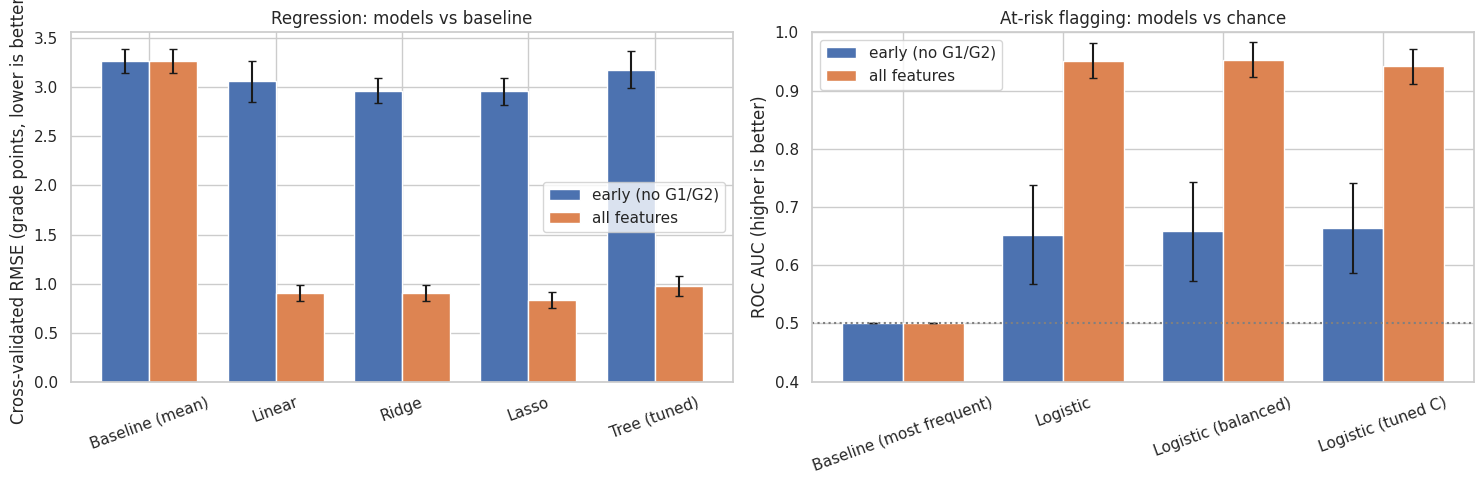

In [11]:
# Cell 8: one summary figure for the report
models_order = ["Baseline (mean)", "Linear", "Ridge", "Lasso", "Tree (tuned)"]
clf_order = ["Baseline (most frequent)", "Logistic", "Logistic (balanced)", "Logistic (tuned C)"]
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for i, fname in enumerate(feature_sets):
    sub = reg_table[reg_table.features == fname].set_index("model").loc[models_order]
    axes[0].bar(np.arange(len(models_order)) + i * width, sub["RMSE"], width,
                yerr=sub["RMSE std"], capsize=3, label=fname)
axes[0].set_xticks(np.arange(len(models_order)) + width / 2)
axes[0].set_xticklabels(models_order, rotation=20)
axes[0].set_ylabel("Cross-validated RMSE (grade points, lower is better)")
axes[0].set_title("Regression: models vs baseline"); axes[0].legend()

for i, fname in enumerate(feature_sets):
    sub = clf_table[clf_table.features == fname].set_index("model").loc[clf_order]
    axes[1].bar(np.arange(len(clf_order)) + i * width, sub["ROC AUC"], width,
                yerr=sub["AUC std"], capsize=3, label=fname)
axes[1].axhline(0.5, color="gray", linestyle=":")
axes[1].set_xticks(np.arange(len(clf_order)) + width / 2)
axes[1].set_xticklabels(clf_order, rotation=20)
axes[1].set_ylabel("ROC AUC (higher is better)"); axes[1].set_ylim(0.4, 1.0)
axes[1].set_title("At-risk flagging: models vs chance"); axes[1].legend()
plt.tight_layout()
plt.savefig("phase3_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# Cell 9: save everything. These files feed Phase 4 and the final report.
reg_table.to_csv("phase3_regression_results.csv", index=False)
clf_table.to_csv("phase3_classification_results.csv", index=False)
paired_tbl.to_csv("phase3_paired_comparison.csv", index=False)

chosen = {"regression": chosen_reg, "classification": chosen_clf,
          "cv": "5-fold x 3 repeats, random_state=42",
          "rules": {"selection": "simplest model within 1 std of the best",
                    "regression_useful": ">=80% folds better than baseline and >=10% lower RMSE",
                    "classification_usable": "ROC AUC >= 0.70"}}
with open("chosen_baselines.json", "w") as f:
    json.dump(chosen, f, indent=2)
print(json.dumps(chosen, indent=2))

{
  "regression": {
    "early (no G1/G2)": {
      "model": "Ridge",
      "cv_rmse": 2.966,
      "relative_gain_pct": 9.2,
      "folds_better": "15/15",
      "useful": false
    },
    "all features": {
      "model": "Ridge",
      "cv_rmse": 0.903,
      "relative_gain_pct": 72.4,
      "folds_better": "15/15",
      "useful": true
    }
  },
  "classification": {
    "early (no G1/G2)": {
      "model": "Logistic",
      "roc_auc": 0.652,
      "pr_auc": 0.442,
      "pr_auc_of_guessing": 0.256,
      "usable": false
    },
    "all features": {
      "model": "Logistic",
      "roc_auc": 0.951,
      "pr_auc": 0.876,
      "pr_auc_of_guessing": 0.256,
      "usable": true
    }
  },
  "cv": "5-fold x 3 repeats, random_state=42",
  "rules": {
    "selection": "simplest model within 1 std of the best",
    "regression_useful": ">=80% folds better than baseline and >=10% lower RMSE",
    "classification_usable": "ROC AUC >= 0.70"
  }
}
